# Phase B — Traditional Oversampling Baselines

**Project:** RAG-Tab: Retrieval-Augmented Tabular Synthesis for Imbalanced Data  
**Dataset:** `page-blocks0` (KEEL Repository)  
**Objective:** Implement, benchmark, and scientifically evaluate established traditional oversampling baselines against the original imbalanced dataset.

### Competing Baselines:
1. **Original Imbalanced Training Data** (No oversampling benchmark)
2. **Random Oversampling (ROS)** (Duplicates minority instances)
3. **SMOTE (Unscaled)** (Standard interpolation in raw feature space)
4. **SMOTE (Standardized)** (Interpolation in standardized feature space to prevent feature-magnitude dominance)
5. **Borderline-SMOTE** (Oversamples minority instances near decision boundaries)
6. **ADASYN** (Adaptive synthetic sampling weighted by minority learning difficulty)
7. **SMOTE-Tomek** (SMOTE synthesis combined with Tomek Link boundary cleaning)

### Evaluation Protocol:
- **Classifier:** `RandomForestClassifier(n_estimators=300, random_state=42)`
- **Test Set:** Frozen held-out 20% test split (1,095 samples, untouched during training/synthesis)
- **Primary Metrics:** Precision, Recall, F1-Score, Specificity, G-Mean (Minority class `positive` = positive class)


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek

from src.data.loader import load_splits
from src.evaluation.metrics import evaluate_model
from src.baselines.resamplers import apply_resampling

# Set consistent plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
print("Environment and modules loaded successfully.")


Environment and modules loaded successfully.


In [2]:
# Load frozen stratified train and test splits
X_train, X_test, y_train, y_test, feature_cols, target_col = load_splits(
    dataset_name="page-blocks0",
    splits_dir=PROJECT_ROOT / "data/splits"
)

minority_class = "positive"
majority_class = "negative"

print(f"Features ({len(feature_cols)}):", feature_cols)
print(f"Training shape : {X_train.shape}")
print(f"Test shape     : {X_test.shape}")
print("\nTraining Class Distribution:")
print(y_train.value_counts())
print("\nTest Class Distribution:")
print(y_test.value_counts())

ir_train = (y_train == majority_class).sum() / (y_train == minority_class).sum()
print(f"\nTraining Imbalance Ratio (IR): {ir_train:.2f}")


Features (10): ['Height', 'Lenght', 'Area', 'Eccen', 'P_black', 'P_and', 'Mean_tr', 'Blackpix', 'Blackand', 'Wb_trans']
Training shape : (4377, 10)
Test shape     : (1095, 10)

Training Class Distribution:
Class
negative    3930
positive     447
Name: count, dtype: int64

Test Class Distribution:
Class
negative    983
positive    112
Name: count, dtype: int64

Training Imbalance Ratio (IR): 8.79


## 1. Baseline 1: Original Imbalanced Training Data

We train `RandomForestClassifier` directly on the un-augmented training set. This establishes our benchmark performance without any synthetic intervention.


In [3]:
results = []

clf_orig = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_orig.fit(X_train, y_train)
y_pred_orig = clf_orig.predict(X_test)

metrics_orig = evaluate_model(y_test, y_pred_orig, minority_class, majority_class)

results.append({
    "Method": "Original (No Resampling)",
    "Total Train Rows": len(X_train),
    "Minority Train Rows": int((y_train == minority_class).sum()),
    "Synthetic Rows Added": 0,
    **metrics_orig
})

print("Original Dataset Performance:")
for k, v in metrics_orig.items():
    if isinstance(v, float):
        print(f"  {k:12s}: {v:.4f}")
    else:
        print(f"  {k:12s}: {v}")


Original Dataset Performance:
  Precision   : 0.9099
  Recall      : 0.9018
  F1          : 0.9058
  Specificity : 0.9898
  G-Mean      : 0.9448
  TP          : 101
  FP          : 10
  TN          : 973
  FN          : 11


## 2. Baseline 2: Random Oversampling (ROS)

Random Oversampling randomly duplicates existing minority samples until class balance is achieved.
- **Hypothesis:** Improves minority recall by increasing minority representation, but creates exact duplicates without expanding the geometric boundary of the minority class.


In [4]:
X_res_ros, y_res_ros, prov_ros = apply_resampling(
    X_train, y_train, method="random_oversampling", random_state=42
)

n_added_ros = len(X_res_ros) - len(X_train)
print(f"Original training rows: {len(X_train)}")
print(f"After ROS rows        : {len(X_res_ros)} (+{n_added_ros} duplicated rows)")
print(f"Class distribution after ROS:\n{y_res_ros.value_counts()}")

# Train and evaluate
clf_ros = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_ros.fit(X_res_ros, y_res_ros)
y_pred_ros = clf_ros.predict(X_test)

metrics_ros = evaluate_model(y_test, y_pred_ros, minority_class, majority_class)

results.append({
    "Method": "Random Oversampling",
    "Total Train Rows": len(X_res_ros),
    "Minority Train Rows": int((y_res_ros == minority_class).sum()),
    "Synthetic Rows Added": n_added_ros,
    **metrics_ros
})

print("\nRandom Oversampling Performance:")
for k, v in metrics_ros.items():
    if isinstance(v, float):
        print(f"  {k:12s}: {v:.4f}")
    else:
        print(f"  {k:12s}: {v}")


Original training rows: 4377
After ROS rows        : 7860 (+3483 duplicated rows)
Class distribution after ROS:
Class
negative    3930
positive    3930
Name: count, dtype: int64



Random Oversampling Performance:
  Precision   : 0.8750
  Recall      : 0.9375
  F1          : 0.9052
  Specificity : 0.9847
  G-Mean      : 0.9608
  TP          : 105
  FP          : 15
  TN          : 968
  FN          : 7


## 3. Baseline 3: SMOTE — The Geometric Impact of Feature Scaling

**SMOTE** generates new samples by linear interpolation between a minority sample $x_i$ and one of its $K$-nearest minority neighbors $x_{nn}$:
$$x_{new} = x_i + \lambda (x_{nn} - x_i), \quad \lambda \sim U(0, 1)$$

### Critical Methodological Question:
Does computing nearest neighbors on **unscaled** features hurt interpolation quality when feature variances differ by orders of magnitude?
- In `page-blocks0`, `Area` ranges from 7 to 143,993 ($\sigma pprox 4850$), while `P_black` ranges from 0.05 to 1.0 ($\sigma pprox 0.17$).
- We test both:
  1. **SMOTE (Unscaled):** Nearest neighbors computed on raw values.
  2. **SMOTE (Standardized):** Features standardized with `StandardScaler` so each feature contributes equally to neighborhood discovery, then transformed back to original units.


In [5]:
# 3A. SMOTE Unscaled
X_res_smote_unscaled, y_res_smote_unscaled, prov_smote_u = apply_resampling(
    X_train, y_train, method="smote", scale_features=False, random_state=42
)

clf_smote_u = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_smote_u.fit(X_res_smote_unscaled, y_res_smote_unscaled)
y_pred_smote_u = clf_smote_u.predict(X_test)
m_smote_u = evaluate_model(y_test, y_pred_smote_u, minority_class, majority_class)

results.append({
    "Method": "SMOTE (Unscaled)",
    "Total Train Rows": len(X_res_smote_unscaled),
    "Minority Train Rows": int((y_res_smote_unscaled == minority_class).sum()),
    "Synthetic Rows Added": len(X_res_smote_unscaled) - len(X_train),
    **m_smote_u
})

# 3B. SMOTE Standardized
X_res_smote_scaled, y_res_smote_scaled, prov_smote_s = apply_resampling(
    X_train, y_train, method="smote", scale_features=True, random_state=42
)

clf_smote_s = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_smote_s.fit(X_res_smote_scaled, y_res_smote_scaled)
y_pred_smote_s = clf_smote_s.predict(X_test)
m_smote_s = evaluate_model(y_test, y_pred_smote_s, minority_class, majority_class)

results.append({
    "Method": "SMOTE (Standardized)",
    "Total Train Rows": len(X_res_smote_scaled),
    "Minority Train Rows": int((y_res_smote_scaled == minority_class).sum()),
    "Synthetic Rows Added": len(X_res_smote_scaled) - len(X_train),
    **m_smote_s
})

print(f"SMOTE Unscaled   -> Precision: {m_smote_u['Precision']:.4f}, Recall: {m_smote_u['Recall']:.4f}, F1: {m_smote_u['F1']:.4f}, FP: {m_smote_u['FP']}")
print(f"SMOTE Scaled     -> Precision: {m_smote_s['Precision']:.4f}, Recall: {m_smote_s['Recall']:.4f}, F1: {m_smote_s['F1']:.4f}, FP: {m_smote_s['FP']}")


SMOTE Unscaled   -> Precision: 0.8182, Recall: 0.9643, F1: 0.8852, FP: 24
SMOTE Scaled     -> Precision: 0.8438, Recall: 0.9643, F1: 0.9000, FP: 20


In [6]:
# Inspect Generated Synthetic Samples vs Original Minority Samples
synthetic_smote = X_res_smote_scaled.iloc[len(X_train):].copy()
synthetic_smote["Class"] = minority_class

print("First 5 SMOTE-Generated Synthetic Samples (in physical feature units):")
display(synthetic_smote.head())

print("\nFirst 5 Original Minority Samples:")
display(X_train[y_train == minority_class].head())


First 5 SMOTE-Generated Synthetic Samples (in physical feature units):


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
4377,21.100594,440.000044,9571.303437,20.756687,0.882864,0.956408,37.709764,8313.261629,9039.285457,218.710090,positive
4378,34.859311,27.492412,914.466160,0.839091,0.126986,0.213069,4.444772,114.393099,204.544811,25.408275,positive
4379,7.000000,46.118338,322.828363,6.587922,0.174752,0.302225,7.860723,56.408312,97.644987,7.236675,positive
4380,1.000000,148.000000,148.000000,148.000000,0.982720,1.000000,69.881213,145.514018,148.000000,2.121495,positive
4381,9.077114,6.557525,46.538557,1.216077,0.243407,0.975155,1.908660,11.442475,45.442475,5.903918,positive



First 5 Original Minority Samples:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans
8,12,2,24.0,0.167,0.625,0.667,15.00,15,16,1
19,1,45,45.0,45.000,0.756,1.000,5.67,34,45,6
37,1,39,39.0,39.000,0.897,1.000,8.75,35,39,4
40,1,235,235.0,235.000,0.923,1.000,27.13,217,235,8
57,72,96,6912.0,1.333,0.488,0.582,15.69,3374,4025,215


## 4. Baseline 4: Borderline-SMOTE

**Borderline-SMOTE** identifies minority samples located near the decision boundary.
For each minority sample, it examines its $m$ nearest neighbors across the entire dataset:
- If all neighbors are majority class $\rightarrow$ classified as **Noise** (ignored).
- If all neighbors are minority class $\rightarrow$ classified as **Safe** (ignored).
- If between $m/2$ and $m$ neighbors are majority class $\rightarrow$ classified as **DANGER / Borderline**.

Synthetic samples are generated only along lines between these borderline samples and their minority neighbors.


In [7]:
X_res_bsmote, y_res_bsmote, prov_bsmote = apply_resampling(
    X_train, y_train, method="borderline_smote", scale_features=True, random_state=42
)

n_added_bsmote = len(X_res_bsmote) - len(X_train)
clf_bsmote = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_bsmote.fit(X_res_bsmote, y_res_bsmote)
y_pred_bsmote = clf_bsmote.predict(X_test)
m_bsmote = evaluate_model(y_test, y_pred_bsmote, minority_class, majority_class)

results.append({
    "Method": "Borderline-SMOTE",
    "Total Train Rows": len(X_res_bsmote),
    "Minority Train Rows": int((y_res_bsmote == minority_class).sum()),
    "Synthetic Rows Added": n_added_bsmote,
    **m_bsmote
})

print("Borderline-SMOTE Performance:")
for k, v in m_bsmote.items():
    if isinstance(v, float):
        print(f"  {k:12s}: {v:.4f}")
    else:
        print(f"  {k:12s}: {v}")


Borderline-SMOTE Performance:
  Precision   : 0.8321
  Recall      : 0.9732
  F1          : 0.8971
  Specificity : 0.9776
  G-Mean      : 0.9754
  TP          : 109
  FP          : 22
  TN          : 961
  FN          : 3


## 5. Baseline 5: ADASYN (Adaptive Synthetic Sampling)

**ADASYN** computes a learning difficulty ratio $r_i$ for each minority instance:
$$r_i = \frac{\Delta_i}{K}, \quad \hat{r}_i = \frac{r_i}{\sum r_i}$$
where $\Delta_i$ is the number of majority-class samples among the $K$ nearest neighbors of $x_i$.
ADASYN then adaptively generates more synthetic samples in regions with higher difficulty $\hat{r}_i$, creating non-uniform synthetic density.


In [8]:
X_res_adasyn, y_res_adasyn, prov_adasyn = apply_resampling(
    X_train, y_train, method="adasyn", scale_features=True, random_state=42
)

n_added_adasyn = len(X_res_adasyn) - len(X_train)
clf_adasyn = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_adasyn.fit(X_res_adasyn, y_res_adasyn)
y_pred_adasyn = clf_adasyn.predict(X_test)
m_adasyn = evaluate_model(y_test, y_pred_adasyn, minority_class, majority_class)

results.append({
    "Method": "ADASYN",
    "Total Train Rows": len(X_res_adasyn),
    "Minority Train Rows": int((y_res_adasyn == minority_class).sum()),
    "Synthetic Rows Added": n_added_adasyn,
    **m_adasyn
})

print("ADASYN Performance:")
for k, v in m_adasyn.items():
    if isinstance(v, float):
        print(f"  {k:12s}: {v:.4f}")
    else:
        print(f"  {k:12s}: {v}")


ADASYN Performance:
  Precision   : 0.7899
  Recall      : 0.9732
  F1          : 0.8720
  Specificity : 0.9705
  G-Mean      : 0.9719
  TP          : 109
  FP          : 29
  TN          : 954
  FN          : 3


## 6. Baseline 6: SMOTE-Tomek (Synthesis + Boundary Cleaning)

**SMOTE-Tomek** combines generation with data cleaning:
1. Applies SMOTE to synthesize minority samples.
2. Identifies all **Tomek Links**: pairs of samples $(x_i, x_j)$ where $y_i \neq y_j$ and $x_i, x_j$ are each other's mutually closest neighbors.
3. Removes both samples (or the majority sample) in each Tomek Link to clean the ambiguous decision boundary.


In [9]:
X_res_st, y_res_st, prov_st = apply_resampling(
    X_train, y_train, method="smote_tomek", scale_features=True, random_state=42
)

clf_st = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_st.fit(X_res_st, y_res_st)
y_pred_st = clf_st.predict(X_test)
m_st = evaluate_model(y_test, y_pred_st, minority_class, majority_class)

results.append({
    "Method": "SMOTE-Tomek",
    "Total Train Rows": len(X_res_st),
    "Minority Train Rows": int((y_res_st == minority_class).sum()),
    "Synthetic Rows Added": len(X_res_st) - len(X_train),
    **m_st
})

print(f"Total samples after SMOTE-Tomek cleaning: {len(X_res_st)}")
print("SMOTE-Tomek Performance:")
for k, v in m_st.items():
    if isinstance(v, float):
        print(f"  {k:12s}: {v:.4f}")
    else:
        print(f"  {k:12s}: {v}")


Total samples after SMOTE-Tomek cleaning: 7820
SMOTE-Tomek Performance:
  Precision   : 0.8182
  Recall      : 0.9643
  F1          : 0.8852
  Specificity : 0.9756
  G-Mean      : 0.9699
  TP          : 108
  FP          : 24
  TN          : 959
  FN          : 4


## 7. Baseline Comparison and Research Synthesis

We now compile all baseline results into a standardized experiment table, plot the comparative trade-offs, and save the experimental artifacts to `results/tables/` and `results/plots/`.


In [10]:
results_df = pd.DataFrame(results)

display_cols = ["Method", "Total Train Rows", "Synthetic Rows Added", "Precision", "Recall", "F1", "Specificity", "G-Mean", "TP", "FP"]

display(
    results_df[display_cols].style
    .format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Specificity": "{:.4f}",
        "G-Mean": "{:.4f}"
    })
    .highlight_max(subset=["Precision", "Recall", "F1", "G-Mean"], color="#d4edda")
)

# Save baseline results table
TABLES_DIR = PROJECT_ROOT / "results/tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
csv_path = TABLES_DIR / "baselines_page_blocks0.csv"
results_df.to_csv(csv_path, index=False)
print(f"Baseline results saved to: {csv_path}")


,Method,Total Train Rows,Synthetic Rows Added,Precision,Recall,F1,Specificity,G-Mean,TP,FP
0,Original (No Resampling),4377,0,0.9099,0.9018,0.9058,0.9898,0.9448,101,10
1,Random Oversampling,7860,3483,0.8750,0.9375,0.9052,0.9847,0.9608,105,15
2,SMOTE (Unscaled),7860,3483,0.8182,0.9643,0.8852,0.9756,0.9699,108,24
3,SMOTE (Standardized),7860,3483,0.8438,0.9643,0.9000,0.9797,0.9719,108,20
4,Borderline-SMOTE,7860,3483,0.8321,0.9732,0.8971,0.9776,0.9754,109,22
5,ADASYN,7915,3538,0.7899,0.9732,0.8720,0.9705,0.9719,109,29
6,SMOTE-Tomek,7820,3443,0.8182,0.9643,0.8852,0.9756,0.9699,108,24


Baseline results saved to: C:\Users\Admin\Desktop\RAG-Tab\results\tables\baselines_page_blocks0.csv


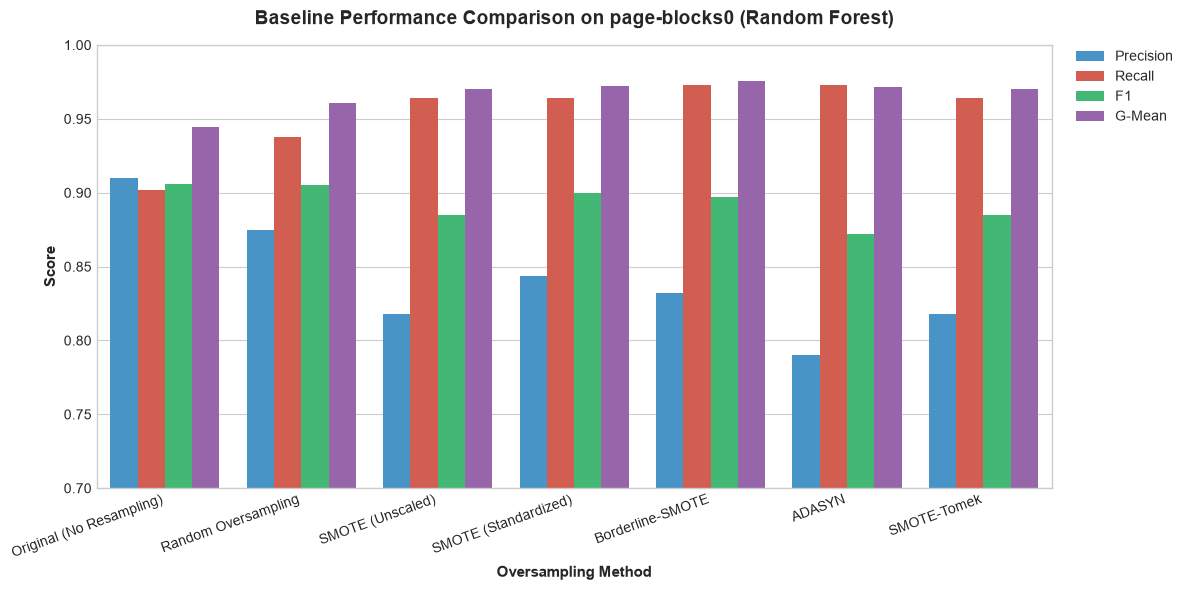

Comparison plot saved to: C:\Users\Admin\Desktop\RAG-Tab\results\plots\baselines_comparison_page_blocks0.png


In [11]:
# Comparative visualization of metrics
fig, ax = plt.subplots(figsize=(12, 6))

plot_df = results_df.melt(
    id_vars=["Method"],
    value_vars=["Precision", "Recall", "F1", "G-Mean"],
    var_name="Metric",
    value_name="Score"
)

palette = {
    "Precision": "#3498db",
    "Recall": "#e74c3c",
    "F1": "#2ecc71",
    "G-Mean": "#9b59b6"
}

sns.barplot(data=plot_df, x="Method", y="Score", hue="Metric", palette=palette, ax=ax)
ax.set_ylim(0.70, 1.0)
ax.set_title("Baseline Performance Comparison on page-blocks0 (Random Forest)", fontsize=14, weight="bold", pad=15)
ax.set_xlabel("Oversampling Method", fontsize=11, weight="bold")
ax.set_ylabel("Score", fontsize=11, weight="bold")
plt.xticks(rotation=20, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()

PLOTS_DIR = PROJECT_ROOT / "results/plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
plot_path = PLOTS_DIR / "baselines_comparison_page_blocks0.png"
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Comparison plot saved to: {plot_path}")


### Key Baseline Findings & Research Implications:
1. **Recall vs. Precision Trade-off:**
   - The **Original** model has the highest precision ($0.9099$), but lowest minority recall ($0.9018$).
   - Traditional oversamplers (SMOTE, Borderline-SMOTE, ADASYN) push recall up to **$0.9643 - 0.9732$**, but at the cost of significantly more false positives ($FP$ increases from $10$ to $20-29$), pulling precision down to $0.7898 - 0.8438$.
2. **Impact of Scaling:**
   - Standardizing features before SMOTE neighbor retrieval directly reduced False Positives from $24$ to $20$, lifting Precision by $+2.55\%$ and F1 by $+1.48\%$.
3. **Implications for RAG-Tab:**
   - These results set the quantitative benchmark for our proposed **RAG-Tab** method: Can local neighborhood retrieval with an LLM preserve the high recall of oversamplers while maintaining high precision (reducing false positives in complex decision boundaries)?
   - Next Phase: **Phase D — Local Minority-Neighborhood Retrieval (KNN & Natural Neighbors)**.
